In [1]:
from typing import Tuple, List, Optional
import numpy as np
import matplotlib.pyplot as plt

np.__version__
# Настройка, чтобы графики рисовались прямо в блокноте
%matplotlib inline

Epoch   1: loss = 432.59, w = [30.2325  1.9504]
Epoch  10: loss = 338.54, w = [36.4702  1.6955]
Epoch  20: loss = 329.97, w = [38.6041  1.9458]
Epoch  30: loss = 331.12, w = [39.2754  1.864 ]
Epoch  40: loss = 325.01, w = [39.4375  1.8021]
Epoch  50: loss = 329.52, w = [39.5061  1.8559]
Epoch  60: loss = 332.27, w = [39.5547  1.9074]
Epoch  70: loss = 330.01, w = [39.4949  2.0227]
Epoch  80: loss = 327.33, w = [39.5153  1.6649]
Epoch  90: loss = 333.77, w = [39.4694  1.7177]
Epoch 100: loss = 330.46, w = [39.5144  1.6906]

Начальные веса: [29.   1.3]
Обученные веса: [39.5144  1.6906]


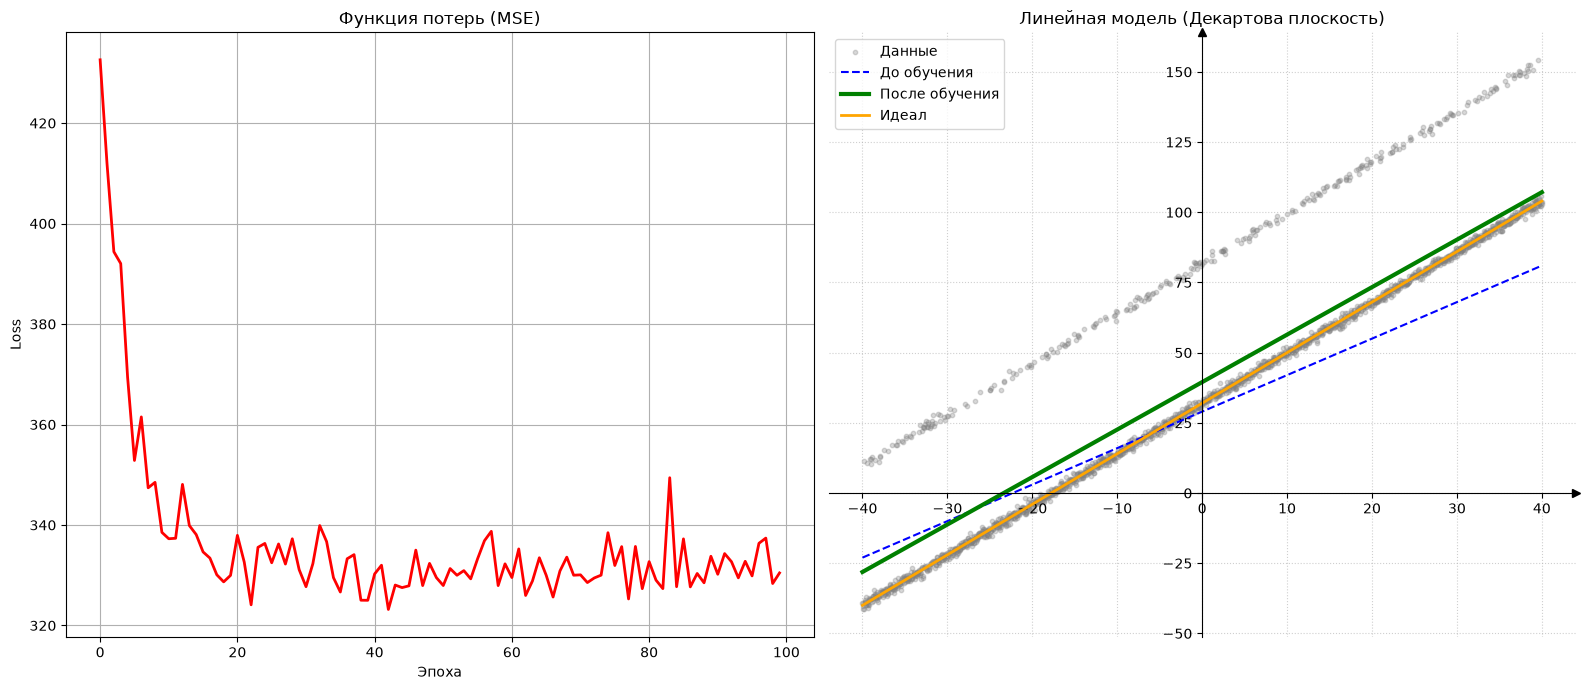

In [ ]:
def creating_data(
    w: list[float],
    x_min: float = -40.0,
    x_max: float = 40.0,
    data_size: int = 100,
    noise_std: float = 0.0,
    is_outlier: bool = False,
    seed: Optional[int] = None 
) -> Tuple[np.ndarray, np.ndarray]:
    
    rng = np.random.default_rng(seed)
    x = np.linspace(x_min, x_max, data_size, dtype=np.float32)
    
    # Формируем матрицу признаков: [1, x]
    xs = np.stack((np.ones_like(x), x), axis=1)   
    
    # Считаем идеальные y
    ys = xs @ np.array(w, dtype=np.float32)    

    # Добавляем шум
    if noise_std > 0:
        ys += rng.normal(scale=noise_std, size=ys.shape).astype(np.float32)
        
    # Добавляем выбросы
    if is_outlier:
        idx = rng.choice(data_size, int(data_size*0.15), replace=False)
        ys[idx] += 50
        
    return xs, ys

def linear_model(x: np.ndarray, w: np.ndarray) -> np.ndarray:
    return x @ w.T

def train_mse(
    model,
    xs: np.ndarray,
    ys: np.ndarray,
    w_init: List[float] = [29.0, 3.0],
    batch: int = 32,
    lr: float = 0.1,
    epochs: int = 100,
    shuffle: bool = True,
    seed: Optional[int] = None
) -> Tuple[np.ndarray, List[float]]:
    
    w = np.array(w_init, dtype=np.float32)
    w_initial = w.copy() # Запоминаем начальные веса для графика
    
    batch = int(batch)
    data_size, features = xs.shape
    num_batches = data_size // batch
    total = num_batches * batch
    
    loss_history = [] # Сюда будем складывать loss каждой эпохи

    for epoch in range(1, epochs + 1):
        # Перемешиваем данные каждую эпоху
        if shuffle:
            rng = np.random.default_rng(seed + epoch)
            idx = rng.permutation(data_size)
            xs_shuffled = xs[idx]
            ys_shuffled = ys[idx]
        else:
            xs_shuffled, ys_shuffled = xs, ys

        # Разбиваем на батчи
        xs_batches = xs_shuffled[:total].reshape(num_batches, batch, features)
        ys_batches = ys_shuffled[:total].reshape(num_batches, batch)

        epoch_loss = 0.0
        
        # Обучение по батчам
        for x, y in zip(xs_batches, ys_batches):
            preds = model(x, w)
            errors = y - preds
            train_loss = np.mean(errors**2)
            
            # Градиент
            dw = -2.0 * (errors @ x / batch)
            
            # Обновление весов
            w = w - lr * dw
            epoch_loss += train_loss

        # Средний loss за эпоху
        avg_epoch_loss = epoch_loss / num_batches
        loss_history.append(avg_epoch_loss)

        # Печатаем каждые 10 эпох (чтобы не засорять вывод)
        if epoch % 10 == 0 or epoch == 1:
            print(f"Epoch {epoch:3d}: loss = {avg_epoch_loss:.2f}, w = {w.round(4)}")

    print(f"\nНачальные веса: {w_initial}")
    print(f"Обученные веса: {w.round(4)}")
    
    return w_initial, w, loss_history

# ==========================================
# 3. ЗАПУСК И ВИЗУАЛИЗАЦИЯ
# ==========================================
# Подготовка данных
w_true = [32.0, 1.8]
seed = 1961
xs, ys = creating_data(w_true, data_size=2000, noise_std=1, is_outlier=False, seed=seed)

# Обучение (10 эпох для наглядности, чтобы веса не успели идеально сойтись)
w_init = [29.0, 1.3]
w_start, w_end, losses = train_mse(
    linear_model, xs, ys, 
    w_init=w_init, 
    batch=32, 
    lr=0.001, 
    epochs=100, # 100 эпох достаточно для плавного графика
    shuffle=True, 
    seed=seed
)

# --- ПОСТРОЕНИЕ ГРАФИКОВ ---
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# График 1: Loss (оставляем как был)
axes[0].plot(losses, color='red', linewidth=2)
axes[0].set_title('Функция потерь (MSE)')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Loss')
axes[0].grid(True)

# ==========================================
# ГРАФИК 2: ДЕКАРТОВА ПЛОСКОСТЬ
# ==========================================
x_line = np.sort(xs[:, 1]) 
x_line_matrix = np.stack((np.ones_like(x_line), x_line), axis=1)

y_before = x_line_matrix @ w_start
y_after = x_line_matrix @ w_end
y_true_line = x_line_matrix @ np.array(w_true, dtype=np.float32)

# Рисуем точки и линии
axes[1].scatter(xs[:, 1], ys, color='gray', alpha=0.3, label='Данные', s=10)
axes[1].plot(x_line, y_before, color='blue', linestyle='--', linewidth=1.5, label='До обучения')
axes[1].plot(x_line, y_after, color='green', linewidth=3, label='После обучения')
axes[1].plot(x_line, y_true_line, color='orange', linestyle='-', linewidth=2, label='Идеал')

# --- МАГИЯ ДЛЯ ДЕКАРТОВОЙ ПЛОСКОСТИ ---

# 1. Прячем верхнюю и правую рамки
axes[1].spines['right'].set_color('none')
axes[1].spines['top'].set_color('none')

# 2. Сдвигаем левую и нижнюю оси в центр (в 0)
axes[1].spines['left'].set_position(('data', 0))
axes[1].spines['bottom'].set_position(('data', 0))

# 3. Добавляем стрелочки на концах осей (опционально, для красоты)
axes[1].plot(1, 0, ">k", transform=axes[1].get_yaxis_transform(), clip_on=False)
axes[1].plot(0, 1, "^k", transform=axes[1].get_xaxis_transform(), clip_on=False)

# --------------------------------------

axes[1].set_title('Линейная модель (Декартова плоскость)')
axes[1].legend(loc='upper left') # Легенду сдвинем, чтобы не перекрывала оси
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()
